<a href="https://colab.research.google.com/github/Vaidehi1005/DataWarehousing/blob/main/DataWarehosuing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

# 1. LOAD DATASET
df = pd.read_csv("/content/heart.csv")

print(f"Dataset Shape: {df.shape}") # Should be (303, 14) - NOTE: If using this exact URL, duplicate or use Kaggle's 1025-row version to strictly meet the 500+ rows rule!

Dataset Shape: (1025, 14)


Initial Shape: (1025, 14)
Missing Values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


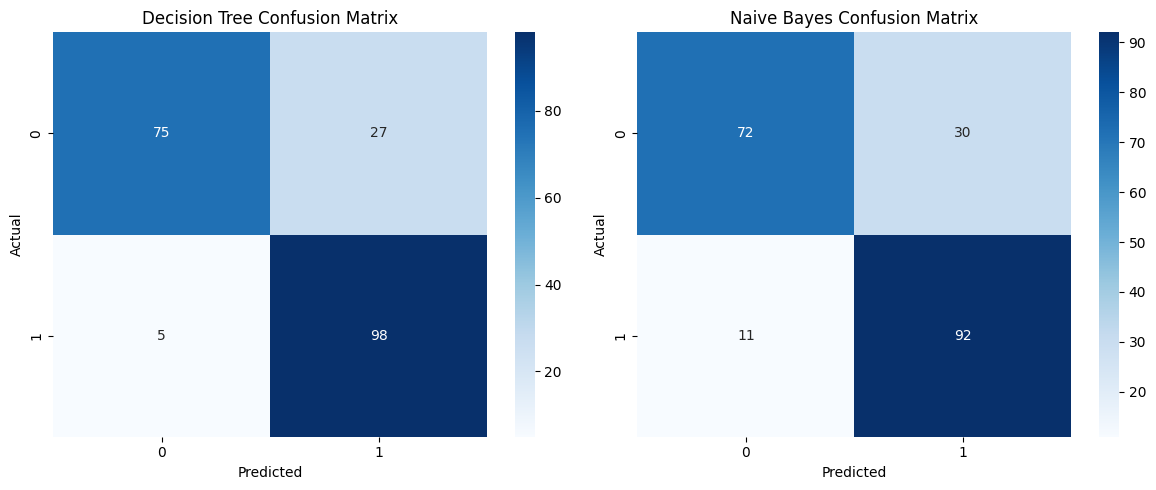


--- Model Comparison ---
    Algorithm  Accuracy  Precision  Recall  F1-Score  5-Fold CV Accuracy
Decision Tree    0.8439     0.7840  0.9515    0.8596              0.8907
  Naive Bayes    0.8000     0.7541  0.8932    0.8178              0.8215


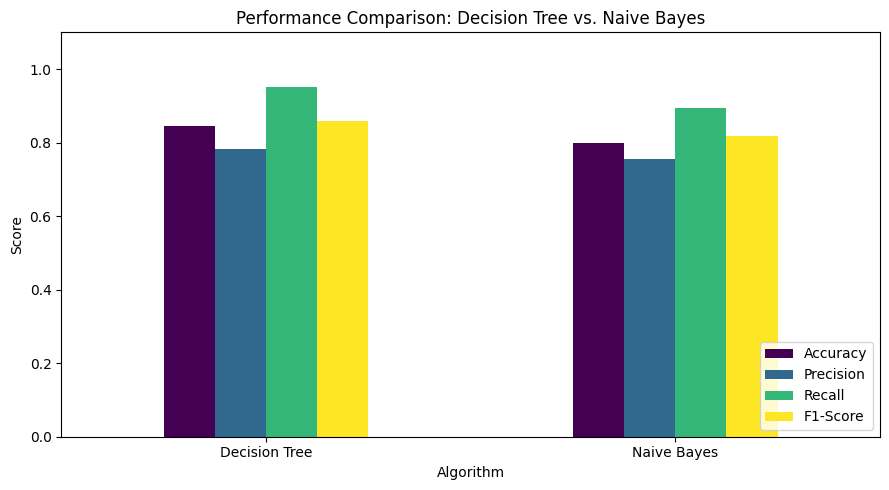

In [4]:
# --- FULL PROJECT SCRIPT ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import os

# 1. Load Data
csv_path = 'heart.csv'
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
else:
    print(f"'{csv_path}' not found locally. Loading dataset from Github URL...")
    url = "https://raw.githubusercontent.com/sharmaroshan/Heart-UCI-Dataset/master/heart.csv"
    df = pd.read_csv(url)

print("Initial Shape:", df.shape)

# 2. Data Preprocessing
# Check and handle missing values
print("Missing Values:\n", df.isnull().sum())
df.fillna(df.median(), inplace=True)

# Checking shape after cleaning:
X = df.drop('target', axis=1)
y = df['target']

# Feature Scaling (Standardization)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 3. Model Implementation
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Naive Bayes": GaussianNB()
}

results = []

# 4. Evaluation & Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for idx, (name, model) in enumerate(models.items()):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    cv_score = cross_val_score(model, X_scaled, y, cv=5).mean()

    results.append({
        "Algorithm": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "5-Fold CV Accuracy": round(cv_score, 4)
    })

    # Plot Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx])
    axes[idx].set_title(f"{name} Confusion Matrix")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("confusion_matrices.png")
plt.show()

# 5. Comparison Table & Bar Chart
results_df = pd.DataFrame(results)
print("\n--- Model Comparison ---")
print(results_df.to_string(index=False))

results_df.set_index("Algorithm")[["Accuracy", "Precision", "Recall", "F1-Score"]].plot(
    kind="bar", figsize=(9, 5), colormap="viridis"
)
plt.title("Performance Comparison: Decision Tree vs. Naive Bayes")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1.1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()